# ForecastIQ — Phase 2: Extended Forecasting Benchmark (4 Demand Workflows + 3 Selection Strategies + Seasonality Diagnostics)

**Beginner-friendly, reproducible experiment:** 100 series per demand type, a shared set of 7 forecasting models, expanding-window cross-validation, and a final untouched 28-day test period.

### New additions
- **MASE** per series and **aggregate WAPE** (with explicit zero-denominator handling).
- **Fair fixed-model comparisons**: every model is evaluated for every category; smoothing parameters are selected using validation only.
- **Selection benefit**: compare each product's CV-selected model against a fixed model chosen solely from validation scores.
- **Simple retail cost proxy**: 28-day understock/overstock costs with explicitly assumed unit penalties (not a realistic inventory simulation).
- **Optional repeated sampling**: assess validation stability using several random samples, without accessing the final test window.

**Important:** M5 records *sales*, which can be affected by stockouts; interpreting sales as true demand is an approximation. We cannot infer real stocking costs from M5 alone.


In [77]:
# Shared scientifically validated ForecastIQ framework
import sys
from pathlib import Path
_project = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(_project) not in sys.path:
    sys.path.insert(0, str(_project))
from src.experiments.config import ExperimentConfig, save_manifest
EXPERIMENT_CONFIG = ExperimentConfig()
EXPERIMENT_NAME = '02_forecasting_4_workflows_10_seeds'
MANIFEST = save_manifest(_project / 'results' / 'manifests' / (EXPERIMENT_NAME + '.json'), EXPERIMENT_NAME, EXPERIMENT_CONFIG, sources=[_project / 'data' / 'raw' / 'sales_train_validation.csv'])
print('Experiment manifest:', MANIFEST['experiment_id'])


Experiment manifest: 02_forecasting_4_workflows_10_seeds-20261101T102913Z


## 1 — Import libraries and locate files

The project path works when you run the notebook from `notebooks/` or from the project root.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit

project = Path.cwd()
if not (project / "data").exists() and (project.parent / "data").exists():
    project = project.parent

folder = project / "data" / "processed"
file_sales = folder / "m5_sample_400.csv"
file_info = folder / "m5_sample_400_metadata.csv"

assert file_sales.exists(), "Run Notebook 1 to create m5_sample_400.csv"
assert file_info.exists(), "Run Notebook 1 to create m5_sample_400_metadata.csv"
print("Project:", project)

## 2 — Load the 400 product–store series

Each row is one item in one store. Daily columns `d_1`, `d_2`, … contain sales in chronological order. We use the category assigned **before the final test window**.

In [79]:
sales = pd.read_csv(file_sales)
info = pd.read_csv(file_info)

day_cols = sorted(
    [col for col in sales.columns if col.startswith("d_")],
    key=lambda col: int(col.split("_")[1])
)

# Join the Phase 1 categories to the sales
sample = sales.merge(info[["series_id", "demand_type"]],
                     on="series_id", validate="one_to_one")

print("Total series:", len(sample))
print(sample["demand_type"].value_counts())
display(sample[["series_id", "demand_type"]].head())

Total series: 400
demand_type
Smooth          100
Erratic         100
Intermittent    100
Lumpy           100
Name: count, dtype: int64


,series_id,demand_type
0,FOODS_2_128__TX_3,Smooth
1,FOODS_3_067__CA_3,Smooth
2,FOODS_2_286__TX_1,Smooth
3,FOODS_2_059__TX_3,Smooth
4,FOODS_2_222__CA_3,Smooth


## 3 — Validate the input and reserve the final 28 days

We **stop** if values are missing, negative, or non-numeric. A missing sale is *not* the same thing as a true zero. The final 28 days are not used for choosing forecasting models.

In [80]:
test_days = 28
validation_days = 28
n_folds = 3

assert len(day_cols) > test_days + n_folds * validation_days, "Too little history"
assert sample["series_id"].is_unique, "Duplicate series IDs"

numbers = sample[day_cols].apply(pd.to_numeric, errors="coerce")
assert numbers.notna().all().all(), "Missing or non-numeric sales detected"
assert (numbers >= 0).all().all(), "Negative sales detected"

sample[day_cols] = numbers
print("History days:", len(day_cols) - test_days)
print("Untouched test days:", test_days)

History days: 1885
Untouched test days: 28


## 3A — Improved seasonality & demand-change analysis (training data only)

We will analyze **all 400 product–store series**, not just one example per category. No observation from the final **28-day test period** is used in this section.

We investigate two separate questions:

1. **Weekly seasonality:** Do sales tend to repeat after 7 or 14 days? We examine ACF and compare weekday average sales. This is *exploratory evidence*, not proof of seasonality.
2. **Recent demand change:** Is demand in the last 90 training days very different from the preceding 90 days? A category like *Smooth* can still exhibit a recent drop to almost zero.

**Important:** The ACF confidence band below is a rough visual reference (±1.96/√n), not a definitive statistical seasonality test. Sparse demand, trends, multiple lags and product availability can make ACF misleading. We will use **cross-validation performance** later to check whether weekly forecasts actually help.

In [ ]:
# Read weekday labels from the official M5 calendar (optional for ACF analysis).
calendar_path = project / "data" / "raw" / "calendar.csv"
weekdays = None
if calendar_path.exists():
    calendar = pd.read_csv(calendar_path, usecols=["d", "weekday"])
    weekdays = dict(zip(calendar["d"], calendar["weekday"]))
else:
    print("Add data/raw/calendar.csv for weekday charts.")

# We select the same four categories used by the forecasting workflows.
categories = ["Smooth", "Erratic", "Intermittent", "Lumpy"]
training_days = day_cols[:-test_days]

def safe_acf(values, lag):
    """Correlation between sales and lagged sales (undefined for constant data)."""
    x = pd.Series(np.asarray(values, dtype=float))
    if len(x) <= lag or x.std() == 0:
        return np.nan
    return float(x.autocorr(lag=lag))

rows = []
for _, row in sample.iterrows():
    history = row[training_days].to_numpy(dtype=float)
    recent = history[-90:]
    previous = history[-180:-90]
    acf_window = history[-180:]
    n = len(acf_window)
    band = 1.96 / np.sqrt(n)

    lag7 = safe_acf(acf_window, 7)
    lag14 = safe_acf(acf_window, 14)
    lag21 = safe_acf(acf_window, 21)
    lag28 = safe_acf(acf_window, 28)

    prev_avg = previous.mean()
    recent_avg = recent.mean()
    # Only calculate percentage change if previous mean > 0.
    change_pct = 100 * (recent_avg / prev_avg - 1) if prev_avg > 0 else np.nan

    rows.append({
        "series_id": row["series_id"],
        "demand_type": row["demand_type"],
        "acf_7": lag7, "acf_14": lag14, "acf_21": lag21, "acf_28": lag28,
        "acf_reference_band": band,
        "weekly_acf_candidate": bool(lag7 > band and lag14 > band),
        "previous_90_mean": prev_avg,
        "recent_90_mean": recent_avg,
        "recent_90_zero_ratio": float(np.mean(recent == 0)),
        "recent_mean_change_pct": change_pct,
        "large_recent_drop": bool(prev_avg > 0 and recent_avg < 0.5 * prev_avg),
    })

seasonality = pd.DataFrame(rows)
print("All training-only series analyzed:", len(seasonality))
display(seasonality.head().round(3))

### 3B — Visualize one example from each group

For each demand type we show **the same last 90 days** in both the daily sales chart and weekday-average chart (when `calendar.csv` exists). This avoids a misleading comparison between different time windows. ACF uses the last **180** training days to give a longer history.

The shaded ACF region is an approximate reference band. A peak above it is *not sufficient* to establish genuine weekly seasonality.

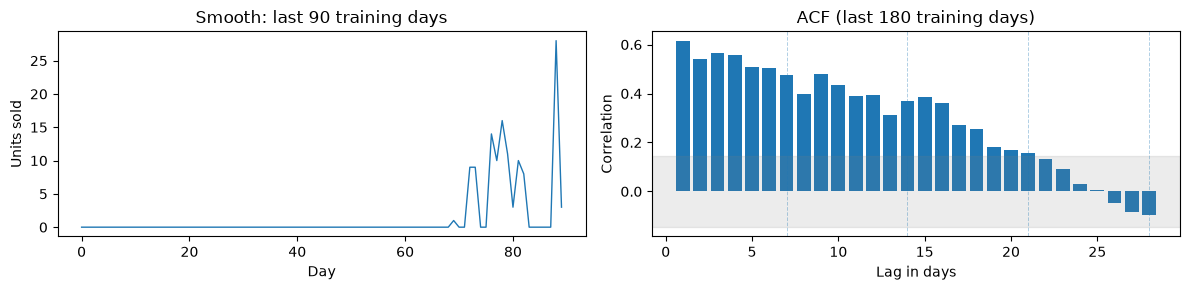

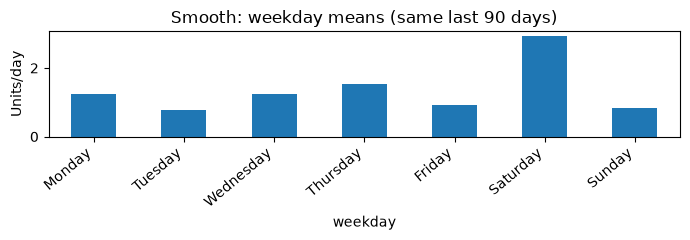

Category: Smooth | Series: FOODS_2_128__TX_3
Lag 7: 0.477 | Lag 14: 0.368


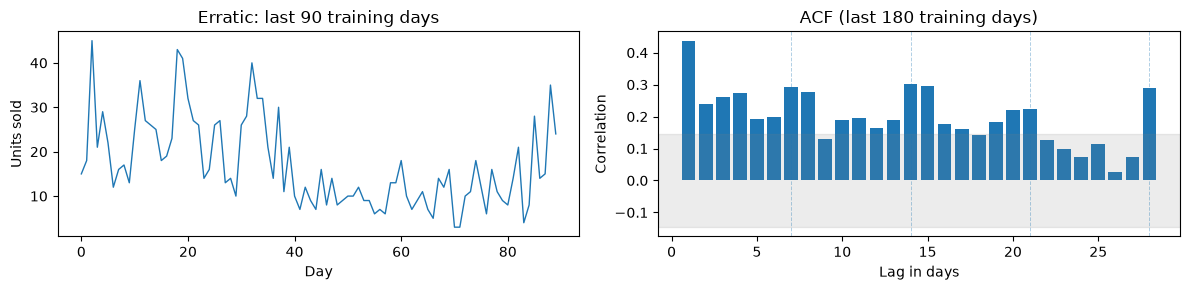

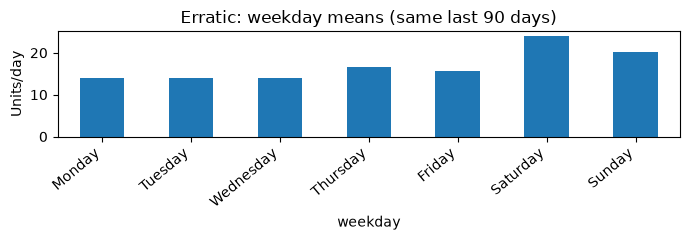

Category: Erratic | Series: FOODS_3_681__CA_1
Lag 7: 0.292 | Lag 14: 0.301


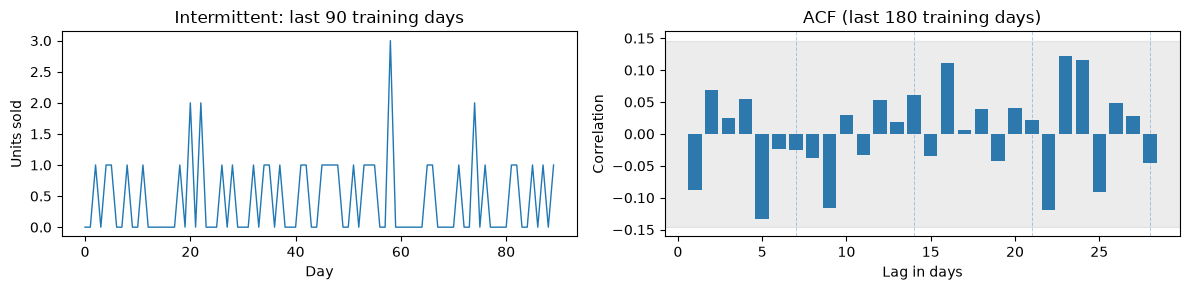

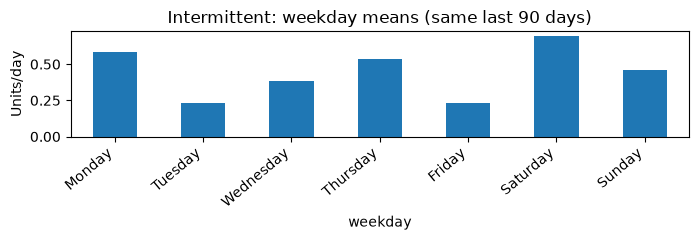

Category: Intermittent | Series: HOBBIES_1_421__WI_1
Lag 7: -0.025 | Lag 14: 0.061


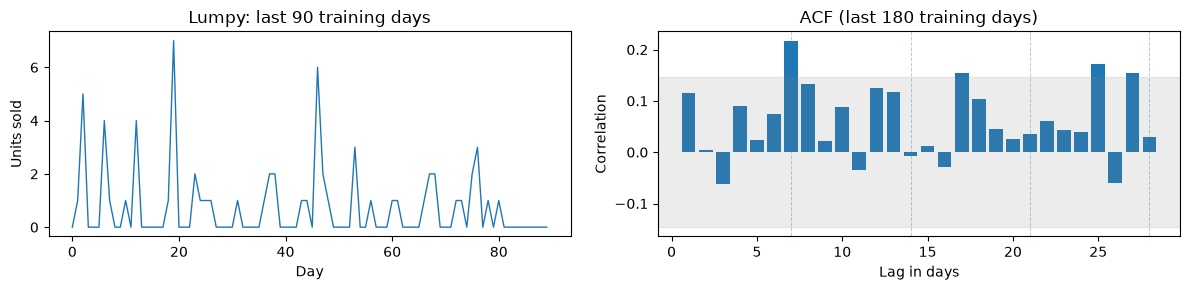

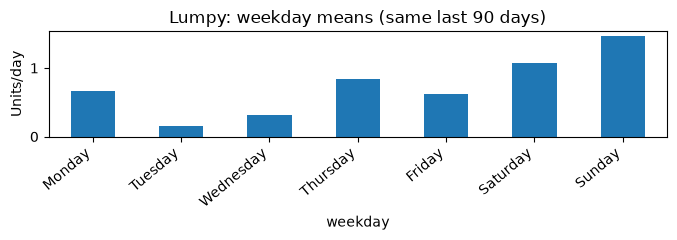

Category: Lumpy | Series: FOODS_2_094__CA_2
Lag 7: 0.217 | Lag 14: -0.008


In [82]:
# Choose one example per category (prefer recent series with some variation).
examples = {}
for category in categories:
    group = sample[sample["demand_type"] == category]
    chosen = group.iloc[0]
    for _, row in group.iterrows():
        recent = row[training_days].to_numpy(dtype=float)[-90:]
        if np.std(recent) > 0 and np.count_nonzero(recent) >= 5:
            chosen = row
            break
    examples[category] = chosen

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
for category, row in examples.items():
    train = row[training_days].to_numpy(dtype=float)
    recent = train[-90:]
    acf_window = train[-180:]
    lags = np.arange(1, 29)
    correlations = [safe_acf(acf_window, lag) for lag in lags]
    reference = 1.96 / np.sqrt(len(acf_window))

    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    axes[0].plot(recent, linewidth=1)
    axes[0].set(title=f"{category}: last 90 training days", xlabel="Day", ylabel="Units sold")
    axes[1].bar(lags, correlations)
    axes[1].axhspan(-reference, reference, color="gray", alpha=0.15)
    for lag in [7, 14, 21, 28]:
        axes[1].axvline(lag, linestyle="--", linewidth=0.7, alpha=0.35)
    axes[1].set(title="ACF (last 180 training days)", xlabel="Lag in days", ylabel="Correlation")
    plt.tight_layout()
    plt.show()

    if weekdays is not None:
        # Day labels match the LAST 90 training observations exactly.
        last90_day_cols = training_days[-90:]
        labels = [weekdays.get(d) for d in last90_day_cols]
        weekday_df = pd.DataFrame({"sales": recent, "weekday": labels})
        means = weekday_df.groupby("weekday")["sales"].mean().reindex(order)
        means.plot(kind="bar", figsize=(7, 2.5), title=f"{category}: weekday means (same last 90 days)")
        plt.ylabel("Units/day")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout()
        plt.show()

    print("Category:", category, "| Series:", row["series_id"])
    print("Lag 7:", round(safe_acf(acf_window, 7), 3),
          "| Lag 14:", round(safe_acf(acf_window, 14), 3))

### 3C — Summary across all sampled products

- `weekly_acf_candidate`: Positive ACF peaks at both lags 7 and 14 above an approximate reference band. **A screening flag, not a confirmed seasonality label.**
- `large_recent_drop`: Recent 90-day average is less than half of the preceding 90-day average. This flags a possible demand regime change for investigation, *not proof of a stockout or product obsolescence*.
- ACF may be weak for intermittent and lumpy demand even if calendar effects exist; a forecasting comparison is essential.

In [83]:
seasonality_summary = seasonality.groupby("demand_type").agg(
    series=("series_id", "count"),
    weekly_acf_candidates=("weekly_acf_candidate", "sum"),
    large_recent_drops=("large_recent_drop", "sum"),
    median_recent_zero_ratio=("recent_90_zero_ratio", "median"),
).reset_index()
seasonality_summary["weekly_candidate_pct"] = (
    100 * seasonality_summary["weekly_acf_candidates"] / seasonality_summary["series"]
)
seasonality_summary["recent_drop_pct"] = (
    100 * seasonality_summary["large_recent_drops"] / seasonality_summary["series"]
)
display(seasonality_summary.round(2))

print("\nSeries with the largest recent demand drops:")
display(seasonality.sort_values("recent_mean_change_pct").head(10)[
    ["series_id", "demand_type", "previous_90_mean", "recent_90_mean", "recent_mean_change_pct"]
].round(2))

,demand_type,series,weekly_acf_candidates,large_recent_drops,median_recent_zero_ratio,weekly_candidate_pct,recent_drop_pct
0,Erratic,100,29,3,0.11,29.0,3.0
1,Intermittent,100,7,10,0.66,7.0,10.0
2,Lumpy,100,16,7,0.49,16.0,7.0
3,Smooth,100,33,2,0.08,33.0,2.0



Series with the largest recent demand drops:


,series_id,demand_type,previous_90_mean,recent_90_mean,recent_mean_change_pct
297,FOODS_2_132__TX_2,Intermittent,0.10,0.00,-100.00
292,FOODS_2_350__CA_4,Intermittent,0.41,0.01,-97.30
286,FOODS_3_577__TX_3,Intermittent,0.26,0.03,-86.96
212,HOUSEHOLD_1_207__WI_1,Intermittent,0.12,0.02,-81.82
381,HOBBIES_2_129__TX_3,Lumpy,2.33,0.44,-80.95
260,HOUSEHOLD_1_077__WI_3,Intermittent,0.31,0.07,-78.57
182,FOODS_3_578__CA_3,Erratic,3.94,0.93,-76.34
298,FOODS_2_354__CA_4,Intermittent,0.39,0.10,-74.29
116,FOODS_3_785__TX_1,Erratic,8.99,2.50,-72.19
262,FOODS_3_745__WI_1,Intermittent,0.47,0.14,-69.05


## 4 — The forecasting methods

All functions below return the **expected number of units per day** for the requested horizon. They are simple baselines and standard intermittent-demand estimators.

- **Average:** mean historical daily sales.
- **Naive:** last observed daily sales value.
- **Seasonal naive:** repeat last week's daily pattern.
- **SES:** simple exponential smoothing (smoothing strength `alpha`).
- **Croston:** smooth positive sales sizes and the intervals between them.
- **SBA:** bias adjustment to Croston.
- **TSB:** smooth sale probability and positive-sales size separately.

We can later expose `predict()` as a tool to our Agentic AI system.

In [84]:
from src.forecasting.statistical_models import (
    forecast_average, forecast_naive, forecast_seasonal_naive, forecast_ses,
    forecast_croston, forecast_sba, forecast_tsb
)
# All seven methods now use the documented shared initialization conventions.


## 5 — Candidate models: fair comparison across all four types

Previously, Smooth/Erratic and Intermittent/Lumpy had different model lists. Here, **every category is offered all seven methods**. The same validation protocol applies to each series. A particular algorithm may still win more often for a given category; that's something we **measure**, rather than assume.


In [85]:
FORECAST_FUNCTIONS = {'Average': forecast_average, 'Naive': forecast_naive,
                      'SeasonalNaive': forecast_seasonal_naive, 'SES': forecast_ses,
                      'Croston': forecast_croston, 'SBA': forecast_sba, 'TSB': forecast_tsb}

def predict(model, train, horizon, alpha=None):
    kwargs = {} if alpha is None else {'alpha': alpha}
    if model not in FORECAST_FUNCTIONS:
        raise ValueError('Unknown model: ' + model)
    return FORECAST_FUNCTIONS[model](train, horizon, **kwargs)

alpha_values = list(EXPERIMENT_CONFIG.alphas)
all_models = list(FORECAST_FUNCTIONS)
workflows = {category: all_models.copy() for category in ['Smooth','Erratic','Intermittent','Lumpy']}
def configurations(category):
    for model in workflows[category]:
        for alpha in (alpha_values if model in ['SES','Croston','SBA','TSB'] else [None]):
            yield model, alpha
print('Candidate settings per category:', len(list(configurations('Smooth'))))


Candidate settings per category: 15


## 6 — Forecasting metrics and cross-validation

- **MAE:** mean absolute error (units/day); lower is better.
- **Bias:** mean(prediction − actual); positive means overforecasting.
- **MASE:** MAE divided by the average absolute *one-day naive change* in the training history. This makes series of different sales scales more comparable, but **MASE is undefined if its scale is zero**. We report `NaN` rather than inventing a value.
- **WAPE:** sum absolute errors divided by sum actual demand, **aggregated across series**; not defined if the combined actual demand is zero. WAPE is sensitive to low-demand periods, so it is not the only metric.

Each validation fold is 28 days. Training expands chronologically; the final 28-day test set stays untouched until model selection finishes.


In [86]:
from src.evaluation.metrics import mae, mase, mean_signed_bias, wape

def bias(actual, predicted):
    return mean_signed_bias(actual, predicted)

def aggregate_wape(table):
    denominator = table['actual_units'].sum()
    return table['abs_error_units'].sum() / denominator if denominator > 0 else np.nan

def evaluate_setting(history, model, alpha):
    cv = TimeSeriesSplit(n_splits=n_folds, test_size=validation_days)
    errors = []
    for train_idx, val_idx in cv.split(history):
        train, actual = history[train_idx], history[val_idx]
        errors.append(mae(actual, predict(model, train, len(actual), alpha)))
    return float(np.mean(errors))


## 7 — Run one workflow: CV selection + all-model comparisons

For every product-store series, we keep the original test window. All 7 models are evaluated on validation folds; parameters for each model are chosen by **validation MAE only**. The selected model is then evaluated once on the test window.

We also save the test forecasts of each model's validation-tuned configuration. Those test comparisons are **diagnostic only**; never use them to reselect a model or tune a parameter.


In [87]:
def run_workflow(category, limit=100, dataset=None, include_all_test=True):
    dataset = sample if dataset is None else dataset
    group = dataset[dataset["demand_type"] == category].head(limit)
    cv_rows, test_rows, forecast_rows, skipped_rows, model_rows = [], [], [], [], []

    for _, row in group.iterrows():
        values = row[day_cols].to_numpy(dtype=float)
        history, test = values[:-test_days], values[-test_days:]

        # Use only training history to find the active period.
        first_positive = np.where(history > 0)[0]
        if len(first_positive) == 0:
            skipped_rows.append({"series_id": row["series_id"], "reason": "No training sales"})
            continue
        history = history[first_positive[0]:]
        if len(history) < n_folds * validation_days + 28:
            skipped_rows.append({"series_id": row["series_id"], "reason": "Insufficient history"})
            continue

        # CV parameter tuning separately for each model.
        model_best = {}
        for model, alpha in configurations(category):
            score = evaluate_setting(history, model, alpha)
            cv_rows.append({"series_id": row["series_id"], "demand_type": category,
                            "model": model, "alpha": alpha, "cv_MAE": score})
            if model not in model_best or score < model_best[model][0]:
                model_best[model] = (score, alpha)

        # Select overall best model using validation scores only.
        best_model = min(model_best, key=lambda m: model_best[m][0])
        best_score, best_alpha = model_best[best_model]
        predicted = np.maximum(predict(best_model, history, test_days, best_alpha), 0)

        test_rows.append({
            "series_id": row["series_id"], "demand_type": category,
            "best_model": best_model, "best_alpha": best_alpha,
            "cv_MAE": best_score, "test_MAE": mae(test, predicted),
            "test_MASE": mase(test, predicted, history),
            "test_bias": bias(test, predicted),
            "actual_units": float(test.sum()),
            "predicted_units": float(predicted.sum()),
            "abs_error_units": float(np.abs(test - predicted).sum())
        })
        for day, (actual, prediction) in enumerate(zip(test, predicted), 1):
            forecast_rows.append({"series_id": row["series_id"],
                                  "demand_type": category, "test_day": day,
                                  "actual": actual, "predicted": prediction})

        # Save all tuned candidate test results for fair diagnostic comparisons.
        if include_all_test:
            for model, (cv_score, alpha) in model_best.items():
                p = np.maximum(predict(model, history, test_days, alpha), 0)
                model_rows.append({"series_id": row["series_id"], "demand_type": category,
                                   "model": model, "alpha": alpha, "cv_MAE": cv_score,
                                   "test_MAE": mae(test, p),
                                   "test_MASE": mase(test, p, history),
                                   "test_bias": bias(test, p),
                                   "actual_units": float(test.sum()),
                                   "predicted_units": float(p.sum()),
                                   "abs_error_units": float(np.abs(test - p).sum())})

    return (pd.DataFrame(cv_rows), pd.DataFrame(test_rows),
            pd.DataFrame(forecast_rows), pd.DataFrame(skipped_rows), pd.DataFrame(model_rows))


## 8 — Quick test (5 series per type)

Run this preview first. The complete experiment follows below. The quick test does **not** alter the dataset or use the final test to tune models.


In [88]:
for category in workflows:
    cv_preview, test_preview, _, skipped_preview, _ = run_workflow(category, limit=5)
    print(category, "— evaluated:", len(test_preview), "— skipped:", len(skipped_preview))
    if len(test_preview):
        display(test_preview[["series_id", "best_model", "test_MAE", "test_MASE"]].head())


Smooth — evaluated: 5 — skipped: 0


,series_id,best_model,test_MAE,test_MASE
0,FOODS_2_128__TX_3,Naive,5.964286,0.844231
1,FOODS_3_067__CA_3,Croston,1.787644,0.771729
2,FOODS_2_286__TX_1,Average,1.716714,0.680317
3,FOODS_2_059__TX_3,SES,1.642857,0.834495
4,FOODS_2_222__CA_3,SBA,2.446656,0.576777


Erratic — evaluated: 5 — skipped: 0


,series_id,best_model,test_MAE,test_MASE
0,FOODS_3_681__CA_1,Average,5.728003,0.663361
1,FOODS_3_672__TX_1,Average,4.234650,1.338420
2,HOUSEHOLD_1_169__CA_3,Average,2.127922,0.891366
3,FOODS_1_018__CA_3,SBA,6.471139,1.305313
4,FOODS_1_043__WI_3,SeasonalNaive,0.000000,0.000000


Intermittent — evaluated: 5 — skipped: 0


,series_id,best_model,test_MAE,test_MASE
0,HOBBIES_1_421__WI_1,Average,0.492993,1.034910
1,HOUSEHOLD_2_296__WI_2,Naive,0.285714,0.886870
2,FOODS_3_085__TX_2,SBA,0.832676,0.982400
3,HOUSEHOLD_1_164__CA_4,Naive,0.821429,1.133421
4,FOODS_3_591__WI_1,SBA,0.502469,0.647674


Lumpy — evaluated: 5 — skipped: 0


,series_id,best_model,test_MAE,test_MASE
0,FOODS_2_094__CA_2,SBA,0.712439,1.012946
1,FOODS_3_420__CA_2,TSB,0.501265,0.651748
2,HOBBIES_1_244__WI_3,SES,3.545277,1.069156
3,HOUSEHOLD_1_374__TX_2,Average,0.700957,0.907575
4,FOODS_3_281__WI_1,SBA,3.250000,1.195395


## 9 — Full experiment on 400 sampled series

This produces both the **CV-selected result for each series** and diagnostic results for all seven methods. It can take time because every smoothing parameter is evaluated on three chronological folds.


In [89]:
all_cv, all_tests, all_forecasts, all_skipped, all_models_test = [], [], [], [], []

for category in workflows:
    print("Running:", category)
    cv_table, test_table, predictions, skipped_table, model_table = run_workflow(category, limit=100)
    all_cv.append(cv_table)
    all_tests.append(test_table)
    all_forecasts.append(predictions)
    all_skipped.append(skipped_table.assign(demand_type=category))
    all_models_test.append(model_table)
    print("Evaluated:", len(test_table), "| Skipped:", len(skipped_table))

cv_results = pd.concat(all_cv, ignore_index=True)
test_results = pd.concat(all_tests, ignore_index=True)
forecasts = pd.concat(all_forecasts, ignore_index=True)
skipped = pd.concat(all_skipped, ignore_index=True)
model_test_results = pd.concat(all_models_test, ignore_index=True)

print("Total evaluated:", len(test_results))
print("Total skipped:", len(skipped))
display(test_results.head())


Running: Smooth
Evaluated: 99 | Skipped: 1
Running: Erratic
Evaluated: 100 | Skipped: 0
Running: Intermittent
Evaluated: 100 | Skipped: 0
Running: Lumpy
Evaluated: 100 | Skipped: 0
Total evaluated: 399
Total skipped: 1


,series_id,demand_type,best_model,best_alpha,cv_MAE,test_MAE,test_MASE,test_bias,actual_units,predicted_units,abs_error_units
0,FOODS_2_128__TX_3,Smooth,Naive,NaN,1.452381,5.964286,0.844231,-5.750000,245.0,84.000000,167.000000
1,FOODS_3_067__CA_3,Smooth,Croston,0.3,1.779117,1.787644,0.771729,-0.001741,115.0,114.951265,50.054023
2,FOODS_2_286__TX_1,Smooth,Average,NaN,2.072456,1.716714,0.680317,0.082760,82.0,84.317280,48.067989
3,FOODS_2_059__TX_3,Smooth,SES,0.2,1.823617,1.642857,0.834495,-0.843388,90.0,66.385137,46.000000
4,FOODS_2_222__CA_3,Smooth,SBA,0.2,3.004204,2.446656,0.576777,0.614922,127.0,144.217829,68.506368


## 9A — Does weekly seasonality actually help forecasting? (validation only)

A large ACF peak is not proof that `SeasonalNaive` will work. We compare each series' **cross-validation MAE** for `SeasonalNaive` versus `Average`, using the SAME expanding-window validation periods (already calculated above).

- `weekly_cv_better`: Seasonal Naive has lower validation MAE than Historical Average.
- `weekly_evidence_both`: Both the exploratory ACF screen and the validation comparison support a weekly pattern.

This is a **diagnostic comparison**, not an extra model-selection step. We do not use final test observations to define these flags; both models remain in the complete benchmark.

In [90]:
# One row per product and model; best alpha per model already selected by CV.
weekly_cv = model_test_results[
    model_test_results["model"].isin(["Average", "SeasonalNaive"])
].pivot(index="series_id", columns="model", values="cv_MAE")

weekly_cv = weekly_cv.rename(columns={
    "Average": "average_cv_mae",
    "SeasonalNaive": "seasonal_naive_cv_mae",
}).reset_index()

seasonality_results = seasonality.merge(weekly_cv, on="series_id", how="left")
seasonality_results["weekly_cv_better"] = (
    seasonality_results["seasonal_naive_cv_mae"] < seasonality_results["average_cv_mae"]
)
seasonality_results["weekly_evidence_both"] = (
    seasonality_results["weekly_acf_candidate"] & seasonality_results["weekly_cv_better"]
)

weekly_summary = seasonality_results.groupby("demand_type").agg(
    series=("series_id", "count"),
    acf_candidates=("weekly_acf_candidate", "sum"),
    seasonal_naive_cv_wins=("weekly_cv_better", "sum"),
    both_signals=("weekly_evidence_both", "sum"),
    recent_demand_drops=("large_recent_drop", "sum"),
).reset_index()
print("Weekly pattern evidence by demand type (validation data only):")
display(weekly_summary)

# Save all training-only diagnostics for the future Data Analysis Agent.
folder.mkdir(parents=True, exist_ok=True)
seasonality_results.to_csv(folder / "phase2_seasonality_by_series.csv", index=False)
weekly_summary.to_csv(folder / "phase2_seasonality_summary.csv", index=False)
print("Saved seasonality diagnostics in data/processed/")

Weekly pattern evidence by demand type (validation data only):


,demand_type,series,acf_candidates,seasonal_naive_cv_wins,both_signals,recent_demand_drops
0,Erratic,100,29,41,16,3
1,Intermittent,100,7,43,3,10
2,Lumpy,100,16,39,8,7
3,Smooth,100,33,9,6,2


Saved seasonality diagnostics in data/processed/


## 10 — Compare categories with scale-aware metrics

For each demand category, report MAE, **mean defined MASE**, bias, and **aggregate WAPE**. A mean of individual WAPE values would overemphasize low-volume products; we aggregate the numerator and denominator first.


In [91]:
summary = test_results.groupby("demand_type").agg(
    series=("series_id", "count"),
    mean_cv_MAE=("cv_MAE", "mean"),
    mean_test_MAE=("test_MAE", "mean"),
    mean_test_MASE=("test_MASE", "mean"),
    valid_MASE=("test_MASE", "count"),
    mean_test_bias=("test_bias", "mean"),
    actual_units=("actual_units", "sum"),
    abs_error_units=("abs_error_units", "sum")
)
summary["aggregate_WAPE"] = summary["abs_error_units"] / summary["actual_units"].replace(0, np.nan)
summary = summary.drop(columns=["abs_error_units"]).round(3)
display(summary)

print("CV-selected models by demand type:")
display(pd.crosstab(test_results["demand_type"], test_results["best_model"]))


,series,mean_cv_MAE,mean_test_MAE,mean_test_MASE,valid_MASE,mean_test_bias,actual_units,aggregate_WAPE
demand_type,,,,,,,,
Erratic,100,3.277,3.579,0.847,100,0.210,14051.0,0.713
Intermittent,100,0.548,0.715,1.203,100,0.002,1693.0,1.183
Lumpy,100,1.302,1.527,1.032,100,-0.021,4971.0,0.860
Smooth,99,2.687,2.644,0.833,99,-0.168,15116.0,0.485


CV-selected models by demand type:


best_model,Average,Croston,Naive,SBA,SES,SeasonalNaive,TSB
demand_type,,,,,,,
Erratic,24,5,7,46,7,2,9
Intermittent,23,3,38,21,6,6,3
Lumpy,23,3,24,26,8,5,11
Smooth,29,10,3,31,15,0,11


## 11 — Visualize results

The following chart compares average test MAE across the four demand types. **Different demand types may have very different sales scales**, so this raw-MAE comparison is descriptive, not a fair normalized ranking of difficulty.

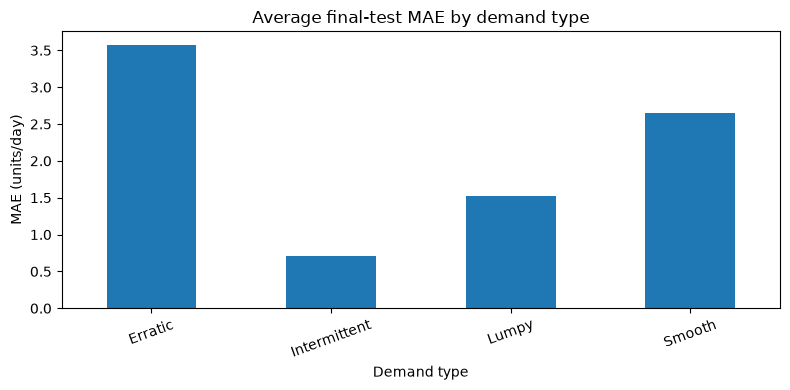

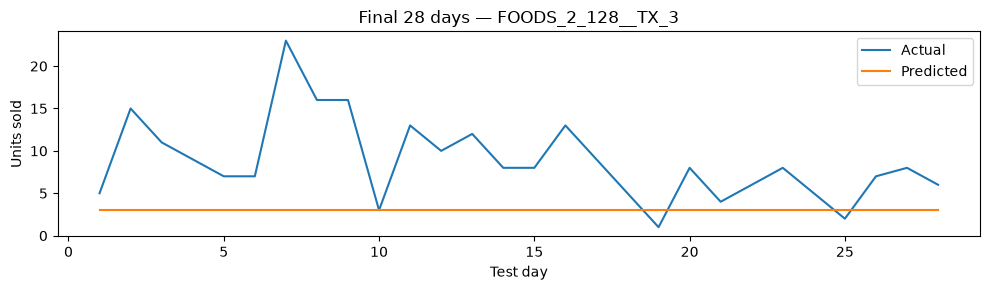

In [92]:
summary["mean_test_MAE"].plot(kind="bar", figsize=(8, 4))
plt.title("Average final-test MAE by demand type")
plt.ylabel("MAE (units/day)")
plt.xlabel("Demand type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Plot the first evaluated product's actual and predicted sales
example_id = test_results.iloc[0]["series_id"]
example = forecasts[forecasts["series_id"] == example_id]
plt.figure(figsize=(10, 3))
plt.plot(example["test_day"], example["actual"], label="Actual")
plt.plot(example["test_day"], example["predicted"], label="Predicted")
plt.title(f"Final 28 days — {example_id}")
plt.xlabel("Test day")
plt.ylabel("Units sold")
plt.legend()
plt.tight_layout()
plt.show()

## 12 — Save results (includes the new metrics)

CSV exports can be reused later by our Agentic AI evaluation agent. Additional reports are exported in the following cells.


In [ ]:
folder.mkdir(parents=True, exist_ok=True)
cv_results.to_csv(folder / "phase2_cv_400.csv", index=False)
test_results.to_csv(folder / "phase2_test_400.csv", index=False)
forecasts.to_csv(folder / "phase2_forecasts_400.csv", index=False)
skipped.to_csv(folder / "phase2_skipped_400.csv", index=False)
model_test_results.to_csv(folder / "phase2_all_models_test_400.csv", index=False)
summary.to_csv(folder / "phase2_summary_4_types.csv")
print("Saved base experiment and all-model comparisons to:", folder)


## 13 — Extra analyses for the ForecastIQ report

The next sections answer four additional research questions:

1. How much does **per-product model selection** help compared with a fixed model?
2. Does the ranking change when we use **MASE and aggregate WAPE** instead of only MAE?
3. How sensitive are our conclusions to different sampled products?
4. How different are forecasts under a **simplified overstock/understock cost scenario**?

All selection decisions must be based on validation scores, **never** on the final test window.


## 14 — Fair model leaderboard by category

Each model's smoothing parameter was tuned using validation data for each series. The test scores below describe performance, but **do not pick the winner after looking at these test results**.


In [94]:
model_leaderboard = model_test_results.groupby(["demand_type", "model"]).agg(
    n=("series_id", "count"),
    mean_cv_MAE=("cv_MAE", "mean"),
    mean_test_MAE=("test_MAE", "mean"),
    mean_test_MASE=("test_MASE", "mean"),
    valid_MASE=("test_MASE", "count"),
    actual_units=("actual_units", "sum"),
    abs_error_units=("abs_error_units", "sum")
).reset_index()
model_leaderboard["aggregate_WAPE"] = (
    model_leaderboard["abs_error_units"] /
    model_leaderboard["actual_units"].replace(0, np.nan)
)
display(model_leaderboard.drop(columns="abs_error_units").round(3))


,demand_type,model,n,mean_cv_MAE,mean_test_MAE,mean_test_MASE,valid_MASE,actual_units,aggregate_WAPE
0,Erratic,Average,100,4.247,4.307,1.014,100,14051.0,0.858
1,Erratic,Croston,100,3.802,3.910,0.931,100,14051.0,0.779
2,Erratic,Naive,100,4.696,4.586,1.070,100,14051.0,0.914
3,Erratic,SBA,100,3.683,3.793,0.909,100,14051.0,0.756
4,Erratic,SES,100,3.507,3.562,0.845,100,14051.0,0.710
5,Erratic,SeasonalNaive,100,4.305,4.233,1.010,100,14051.0,0.844
6,Erratic,TSB,100,3.500,3.553,0.841,100,14051.0,0.708
7,Intermittent,Average,100,0.741,0.772,1.181,100,1693.0,1.276
8,Intermittent,Croston,100,0.803,0.872,1.222,100,1693.0,1.442
9,Intermittent,Naive,100,0.781,0.747,1.260,100,1693.0,1.235


## 15 — Compare three model-selection strategies (validation-only decisions)

We now compare **three different ways to choose a forecasting method** on the exact same evaluated product-store series:

1. **Global selection** — choose **one** forecasting method with the lowest average cross-validation MAE across all product-store series; apply that method to everyone.
2. **Per-demand-type selection** — choose **one** method for each demand category (Smooth, Erratic, Intermittent, Lumpy) using average cross-validation MAE for that category; apply it to all series in that category.
3. **Per-product-store selection** — choose the lowest-CV-MAE method separately for each series.

**Important:** Model identity and smoothing parameters come from *validation* only. We then compare all strategies on the same held-out final 28 days. The results of the test set must **not** be used to change our choices.

Each candidate model's smoothing parameter is tuned per series using CV, even for the fixed global/category *method* strategies. Thus, these strategies fix **the model family**, not one single model instance/alpha for all products. This is an important limitation to explain in an interview.

Since the 400-series sample is balanced across categories, the global choice here is best for this balanced pilot—not necessarily for the original M5 demand distribution.

In [95]:
# STEP 1: Select model families using validation MAE only.
# model_test_results has one row per evaluated series and model.
category_cv = (model_test_results.groupby(["demand_type", "model"])["cv_MAE"]
               .mean().reset_index())
category_winners = category_cv.loc[category_cv.groupby("demand_type")["cv_MAE"].idxmin()].copy()
category_winners = category_winners.rename(columns={"model": "selected_model", "cv_MAE": "mean_validation_MAE"})

fixed_category = dict(zip(category_winners["demand_type"], category_winners["selected_model"]))
global_cv = model_test_results.groupby("model")["cv_MAE"].mean().sort_values()
fixed_global = global_cv.index[0]

print("Selected model for ALL products (global):", fixed_global)
print("\nSelected model for EACH demand type:")
display(category_winners.sort_values("demand_type").round(3))
print("\nGlobal CV leaderboard (balanced sample):")
display(global_cv.rename("mean_cv_MAE").reset_index().round(3))

# STEP 2: The per-series strategy was already selected in run_workflow().
# For the other strategies, find the corresponding tuned model's held-out test scores.
per_series = test_results.copy()
per_series["strategy"] = "Per-product-store"

per_type = model_test_results.copy()
per_type = per_type[per_type.apply(
    lambda row: row["model"] == fixed_category[row["demand_type"]], axis=1
)].copy()
per_type["strategy"] = "Per-demand-type"

global_strategy = model_test_results[model_test_results["model"] == fixed_global].copy()
global_strategy["strategy"] = "Global"

columns = ["series_id", "demand_type", "strategy", "test_MAE", "test_MASE", "test_bias",
           "actual_units", "predicted_units", "abs_error_units"]
comparison = pd.concat([
    per_series[columns], per_type[columns], global_strategy[columns]
], ignore_index=True)

# All three strategies MUST cover exactly the same evaluated series.
expected_ids = set(test_results["series_id"])
for strategy, group in comparison.groupby("strategy"):
    assert set(group["series_id"]) == expected_ids, f"Missing series for {strategy}"
    assert group["series_id"].is_unique, f"Duplicate series for {strategy}"
print("\nEvaluated series per strategy:")
print(comparison["strategy"].value_counts())

# STEP 3: Test metrics by demand type and strategy.
strategy_summary = comparison.groupby(["strategy", "demand_type"]).agg(
    series=("series_id", "count"),
    mean_MAE=("test_MAE", "mean"),
    mean_MASE=("test_MASE", "mean"),
    valid_MASE=("test_MASE", "count"),
    mean_bias=("test_bias", "mean"),
    actual_units=("actual_units", "sum"),
    abs_error_units=("abs_error_units", "sum")
).reset_index()
strategy_summary["aggregate_WAPE"] = (
    strategy_summary["abs_error_units"] /
    strategy_summary["actual_units"].replace(0, np.nan)
)
display(strategy_summary.drop(columns="abs_error_units").round(3))

Selected model for ALL products (global): TSB

Selected model for EACH demand type:


,demand_type,selected_model,mean_validation_MAE
6,Erratic,TSB,3.500
13,Intermittent,TSB,0.600
18,Lumpy,SES,1.418
27,Smooth,TSB,2.793



Global CV leaderboard (balanced sample):


,model,mean_cv_MAE
0,TSB,2.076
1,SES,2.080
2,SBA,2.188
3,Croston,2.246
4,Average,2.419
5,SeasonalNaive,2.561
6,Naive,2.830



Evaluated series per strategy:
strategy
Per-product-store    399
Per-demand-type      399
Global               399
Name: count, dtype: int64


,strategy,demand_type,series,mean_MAE,mean_MASE,valid_MASE,mean_bias,actual_units,aggregate_WAPE
0,Global,Erratic,100,3.553,0.841,100,0.349,14051.0,0.708
1,Global,Intermittent,100,0.667,1.130,100,-0.023,1693.0,1.104
2,Global,Lumpy,100,1.541,1.035,100,0.144,4971.0,0.868
3,Global,Smooth,99,2.524,0.816,99,0.031,15116.0,0.463
4,Per-demand-type,Erratic,100,3.553,0.841,100,0.349,14051.0,0.708
5,Per-demand-type,Intermittent,100,0.667,1.130,100,-0.023,1693.0,1.104
6,Per-demand-type,Lumpy,100,1.533,1.025,100,0.127,4971.0,0.864
7,Per-demand-type,Smooth,99,2.524,0.816,99,0.031,15116.0,0.463
8,Per-product-store,Erratic,100,3.579,0.847,100,0.210,14051.0,0.713
9,Per-product-store,Intermittent,100,0.715,1.203,100,0.002,1693.0,1.183


### 15A — Overall strategy performance (all 399 evaluated series)

Now summarize the same predictions across all demand types. The resulting **MAE, MASE, bias and WAPE** let us ask whether category-level or per-product-store selection improved outcomes relative to a single global method. Note that raw MAE and WAPE weight high-volume series more heavily; we show MASE as an additional scale-aware perspective.

Do not infer that per-product selection is always best: per-series tuning can overfit noisy validation windows.

,strategy,series,mean_MAE,mean_MASE,valid_MASE,mean_bias,actual_units,aggregate_WAPE
0,Global,399,2.070,0.956,399,0.125,35831.0,0.645
1,Per-demand-type,399,2.068,0.953,399,0.121,35831.0,0.645
2,Per-product-store,399,2.115,0.979,399,0.006,35831.0,0.659


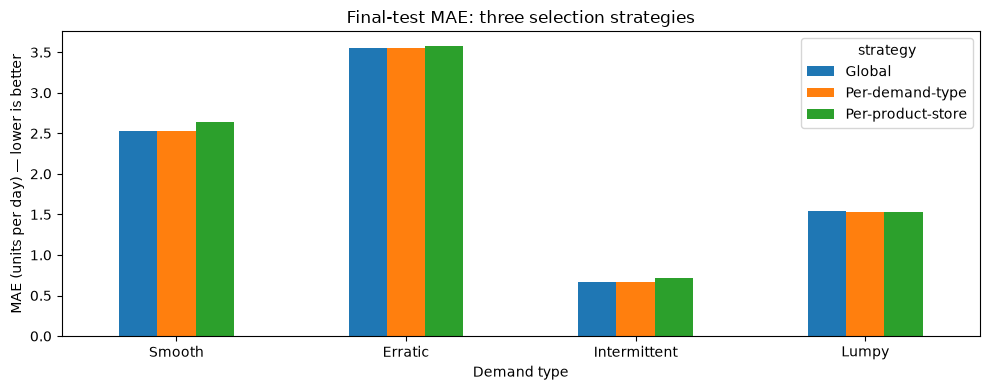

In [96]:
overall_strategy = comparison.groupby("strategy").agg(
    series=("series_id", "count"),
    mean_MAE=("test_MAE", "mean"),
    mean_MASE=("test_MASE", "mean"),
    valid_MASE=("test_MASE", "count"),
    mean_bias=("test_bias", "mean"),
    actual_units=("actual_units", "sum"),
    abs_error_units=("abs_error_units", "sum")
).reset_index()
overall_strategy["aggregate_WAPE"] = (
    overall_strategy["abs_error_units"] /
    overall_strategy["actual_units"].replace(0, np.nan)
)
display(overall_strategy.drop(columns="abs_error_units").round(3))

# Visual comparison of average final-test MAE by demand category
pivot = strategy_summary.pivot(index="demand_type", columns="strategy", values="mean_MAE")
pivot.reindex(["Smooth", "Erratic", "Intermittent", "Lumpy"]).plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Final-test MAE: three selection strategies")
plt.ylabel("MAE (units per day) — lower is better")
plt.xlabel("Demand type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 15B — Which products receive different model choices?

A demand category may have one shared model, while the individual product-store workflow can select a different model. This table helps explain how the three policies behave, even before comparing their test errors.

In [97]:
choices = test_results[["series_id", "demand_type", "best_model"]].copy()
choices = choices.rename(columns={"best_model": "per_product_model"})
choices["per_type_model"] = choices["demand_type"].map(fixed_category)
choices["global_model"] = fixed_global
choices["product_differs_from_type"] = (
    choices["per_product_model"] != choices["per_type_model"]
)
print("Products where per-series and per-demand-type choices differ:",
      int(choices["product_differs_from_type"].sum()), "/", len(choices))
display(choices.head(12))

print("\nDifference rate by demand type:")
display((choices.groupby("demand_type")["product_differs_from_type"]
         .mean().mul(100).rename("percent_different").round(1)))

Products where per-series and per-demand-type choices differ: 368 / 399


,series_id,demand_type,per_product_model,per_type_model,global_model,product_differs_from_type
0,FOODS_2_128__TX_3,Smooth,Naive,TSB,TSB,True
1,FOODS_3_067__CA_3,Smooth,Croston,TSB,TSB,True
2,FOODS_2_286__TX_1,Smooth,Average,TSB,TSB,True
3,FOODS_2_059__TX_3,Smooth,SES,TSB,TSB,True
4,FOODS_2_222__CA_3,Smooth,SBA,TSB,TSB,True
5,HOUSEHOLD_1_071__TX_2,Smooth,SBA,TSB,TSB,True
6,FOODS_3_156__CA_4,Smooth,SBA,TSB,TSB,True
7,HOUSEHOLD_1_277__WI_3,Smooth,TSB,TSB,TSB,False
8,FOODS_3_087__CA_3,Smooth,Average,TSB,TSB,True
9,FOODS_3_668__CA_4,Smooth,SBA,TSB,TSB,True



Difference rate by demand type:


demand_type
Erratic         91.0
Intermittent    97.0
Lumpy           92.0
Smooth          88.9
Name: percent_different, dtype: float64

### 15C — Inventory-cost proxy by selection strategy

We already have an illustrative overstock/understock cost measure below for individual models. Here we **add the same proxy for all three selection strategies**. We compare forecasted total units vs actual total units across 28 days, not real inventory or order decisions.

In [98]:
shortage_penalty_strategy = 5.0  # Example cost per underestimated unit
holding_penalty_strategy = 1.0   # Example cost per overestimated unit

strategy_costs = comparison.copy()
strategy_costs["under_units"] = np.maximum(
    strategy_costs["actual_units"] - strategy_costs["predicted_units"], 0)
strategy_costs["over_units"] = np.maximum(
    strategy_costs["predicted_units"] - strategy_costs["actual_units"], 0)
strategy_costs["proxy_cost"] = (
    shortage_penalty_strategy * strategy_costs["under_units"]
    + holding_penalty_strategy * strategy_costs["over_units"]
)
strategy_cost_summary = strategy_costs.groupby(["strategy", "demand_type"]).agg(
    series=("series_id", "count"),
    average_proxy_cost=("proxy_cost", "mean"),
    total_proxy_cost=("proxy_cost", "sum")
).reset_index()
display(strategy_cost_summary.round(2))

,strategy,demand_type,series,average_proxy_cost,total_proxy_cost
0,Global,Erratic,100,144.12,14411.94
1,Global,Intermittent,100,26.66,2666.33
2,Global,Lumpy,100,44.74,4474.42
3,Global,Smooth,99,71.83,7110.90
4,Per-demand-type,Erratic,100,144.12,14411.94
5,Per-demand-type,Intermittent,100,26.66,2666.33
6,Per-demand-type,Lumpy,100,45.25,4525.03
7,Per-demand-type,Smooth,99,71.83,7110.90
8,Per-product-store,Erratic,100,155.19,15519.35
9,Per-product-store,Intermittent,100,34.38,3438.16


## 16 — Illustrative inventory cost proxy (not a full stock simulation)

For each series, we *hypothetically* order enough stock to cover the **sum of the 28 daily point forecasts**. We compare that quantity with total actual 28-day sales:

- `understock_units = max(actual total − order, 0)`
- `overstock_units = max(order − actual total, 0)`
- `proxy_cost = shortage_penalty × understock_units + holding_penalty × overstock_units`

We assume a **shortage penalty of 5** and an **overstock penalty of 1**, in arbitrary cost units. This is a deliberately simple one-shot planning proxy; it **does not model** supplier lead times, daily inventory balances, lost sales, substitutions, or service levels. Costs are scenario assumptions, not values from M5.


In [99]:
shortage_penalty = 5.0
holding_penalty = 1.0

# The same proxy for the CV-selected strategy and all individually tuned models.
selected_costs = test_results[["series_id", "demand_type", "actual_units", "predicted_units"]].copy()
selected_costs["strategy"] = "Per-series CV selection"

all_costs = model_test_results[["series_id", "demand_type", "actual_units", "predicted_units", "model"]].copy()
all_costs["strategy"] = "Model: " + all_costs["model"]
all_costs = all_costs.drop(columns="model")

cost_table = pd.concat([selected_costs, all_costs], ignore_index=True)
cost_table["understock_units"] = np.maximum(cost_table["actual_units"] - cost_table["predicted_units"], 0)
cost_table["overstock_units"] = np.maximum(cost_table["predicted_units"] - cost_table["actual_units"], 0)
cost_table["proxy_cost"] = (shortage_penalty * cost_table["understock_units"] +
                             holding_penalty * cost_table["overstock_units"])

cost_summary = cost_table.groupby(["demand_type", "strategy"]).agg(
    series=("series_id", "count"), mean_proxy_cost=("proxy_cost", "mean"),
    total_shortage=("understock_units", "sum"),
    total_overstock=("overstock_units", "sum")
).reset_index()
display(cost_summary.round(2))


,demand_type,strategy,series,mean_proxy_cost,total_shortage,total_overstock
0,Erratic,Model: Average,100,148.06,1789.13,5860.80
1,Erratic,Model: Croston,100,141.89,1971.29,4332.07
2,Erratic,Model: Naive,100,271.85,4110.00,6635.00
3,Erratic,Model: SBA,100,161.07,2513.59,3539.04
4,Erratic,Model: SES,100,147.72,2306.79,3237.78
5,Erratic,Model: SeasonalNaive,100,180.39,2983.00,3124.00
6,Erratic,Model: TSB,100,144.12,2239.30,3215.42
7,Erratic,Per-series CV selection,100,155.19,2488.44,3077.14
8,Intermittent,Model: Average,100,29.32,474.63,559.01
9,Intermittent,Model: Croston,100,30.12,413.39,945.43


## 17 — Robustness test: 10 random samples (validation only)

We repeat the category-level model comparison with **10 reproducible random seeds**, taking **20 product–store series per category in each repetition**. For each sampled series and model we calculate cross-validation MAE and keep its best tested smoothing parameter. We then average scores within a category/sample and choose the lowest-MAE model.

The goal is to determine **whether model selection changes when we sample different products**. These samples can overlap, and each seed may include products with different sales volumes. Therefore, compare **which models win, how close the candidates are, and their rankings**, rather than interpreting differences in raw MAE between seeds as an improvement over time. All evaluation uses only the history before the final 28-day test period.

> This is an optional computationally expensive experiment. Set `RUN_REPEAT_SAMPLING = False` to skip it or reduce `N_SEEDS` while testing. The original 400-series experiment is unchanged.

In [ ]:
# Repeated sampling: same method, but 10 random seeds instead of 3.
RUN_REPEAT_SAMPLING = True
N_SEEDS = 10
N_PER_TYPE = 20  # Increase later if you want a stronger robustness test.
SEEDS = [7, 21, 42, 73, 101, 123, 202, 314, 777, 2026][:N_SEEDS]

if RUN_REPEAT_SAMPLING:
    raw_file = project / "data" / "raw" / "sales_train_validation.csv"
    stats_file = folder / "phase1_statistics.csv"
    assert raw_file.exists() and stats_file.exists(), "Run Notebook 1 first."

    stats_all = pd.read_csv(stats_file)
    raw_all = pd.read_csv(raw_file, usecols=["item_id", "store_id"] + day_cols)
    raw_all["series_id"] = raw_all["item_id"] + "__" + raw_all["store_id"]
    raw_all = raw_all.merge(
        stats_all[["item_id", "store_id", "demand_type"]],
        on=["item_id", "store_id"], validate="one_to_one"
    )

    stability_rows = []
    for seed in SEEDS:
        print("Evaluating seed:", seed)
        for category in workflows:
            eligible = raw_all[raw_all["demand_type"] == category]
            group = eligible.sample(n=min(N_PER_TYPE, len(eligible)), random_state=seed)
            for _, row in group.iterrows():
                history = row[day_cols].to_numpy(dtype=float)[:-test_days]
                positive = np.where(history > 0)[0]
                if not len(positive):
                    continue
                history = history[positive[0]:]
                if len(history) < n_folds * validation_days + 28:
                    continue
                for model, alpha in configurations(category):
                    stability_rows.append({
                        "seed": seed, "demand_type": category,
                        "series_id": row["series_id"], "model": model,
                        "cv_MAE": evaluate_setting(history, model, alpha)
                    })

    stability = pd.DataFrame(stability_rows)
    # For every series, keep the best alpha of each model (based on CV only).
    stability_best = stability.groupby(
        ["seed", "demand_type", "series_id", "model"], as_index=False
    )["cv_MAE"].min()

    # Compare models within the same sampled group of products.
    stability_summary = stability_best.groupby(
        ["seed", "demand_type", "model"], as_index=False
    ).agg(cv_MAE=("cv_MAE", "mean"), series=("series_id", "nunique"))

    stability_summary["rank"] = stability_summary.groupby(
        ["seed", "demand_type"]
    )["cv_MAE"].rank(method="min")

    stability_winners = stability_summary.loc[
        stability_summary.groupby(["seed", "demand_type"])["cv_MAE"].idxmin()
    ].sort_values(["demand_type", "seed"])

    # Frequency of each winner across seeds.
    winner_counts = stability_winners.groupby(
        ["demand_type", "model"]
    ).size().reset_index(name="wins")
    winner_counts["win_rate_pct"] = 100 * winner_counts["wins"] / len(SEEDS)

    # Average rank of each model; lower means more consistent competitiveness.
    model_ranks = stability_summary.groupby(
        ["demand_type", "model"], as_index=False
    ).agg(mean_rank=("rank", "mean"), mean_cv_MAE=("cv_MAE", "mean"))

    # Winning margin: difference in CV-MAE between the best and second-best model.
    margins = []
    for (seed, category), group in stability_summary.groupby(["seed", "demand_type"]):
        ordered = group.sort_values("cv_MAE")
        margins.append({
            "seed": seed, "demand_type": category,
            "winner": ordered.iloc[0]["model"],
            "winning_margin_MAE": ordered.iloc[1]["cv_MAE"] - ordered.iloc[0]["cv_MAE"]
        })
    winning_margins = pd.DataFrame(margins)

    print("\nWinner by seed and demand type:")
    display(stability_winners[["seed", "demand_type", "model", "cv_MAE", "series"]])
    print("\nHow often each model wins:")
    display(winner_counts.sort_values(["demand_type", "wins"], ascending=[True, False]))
    print("\nAverage ranks across seeds (lower = better):")
    display(model_ranks.sort_values(["demand_type", "mean_rank"]))
    print("\nWinning margin to second-best model:")
    display(winning_margins)

    folder.mkdir(parents=True, exist_ok=True)
    stability_summary.to_csv(folder / "phase2_repeat_sampling_cv.csv", index=False)
    stability_best.to_csv(folder / "phase2_repeat_sampling_per_series.csv", index=False)
    stability_winners.to_csv(folder / "phase2_repeat_sampling_winners.csv", index=False)
    winner_counts.to_csv(folder / "phase2_repeat_sampling_win_counts.csv", index=False)
    model_ranks.to_csv(folder / "phase2_repeat_sampling_ranks.csv", index=False)
    winning_margins.to_csv(folder / "phase2_repeat_sampling_margins.csv", index=False)
    print("\nSaved six repeated-sampling CSV files in", folder)
else:
    print("Optional repeated-sampling experiment skipped.")

## 18 — Export the extended results and interpret carefully

The validation-vs-test distinction matters: selection decisions come from cross-validation; test metrics are reported afterward. Compare both **forecast accuracy** and **decision costs**, but do not claim that agentic AI improved performance yet; no agents have been implemented.


In [101]:
model_leaderboard.to_csv(folder / "phase2_model_leaderboard.csv", index=False)
strategy_summary.to_csv(folder / "phase2_strategy_comparison.csv", index=False)
cost_summary.to_csv(folder / "phase2_inventory_cost_proxy.csv", index=False)

print("Extra CSV outputs saved:")
print(" - phase2_model_leaderboard.csv")
print(" - phase2_strategy_comparison.csv")
print(" - phase2_inventory_cost_proxy.csv")

print("\nInterpretation reminders:")
print("1. Evaluate per-series selection against the fixed baselines, not just model counts.")
print("2. MASE can be undefined for a constant training series; check valid_MASE.")
print("3. WAPE is aggregated: sum absolute errors / sum actual units.")
print("4. The inventory cost proxy uses assumptions, not real stock information.")
print("5. This pilot is balanced by category, not representative of the full M5 mix.")


# Additional strategy comparison outputs
category_winners.to_csv(folder / "phase2_models_selected_per_demand_type.csv", index=False)
overall_strategy.to_csv(folder / "phase2_strategy_overall.csv", index=False)
choices.to_csv(folder / "phase2_model_choices_per_series.csv", index=False)
comparison.to_csv(folder / "phase2_strategy_per_series_metrics.csv", index=False)
strategy_cost_summary.to_csv(folder / "phase2_strategy_inventory_proxy.csv", index=False)
print("Saved three-strategy comparison outputs.")

Extra CSV outputs saved:
 - phase2_model_leaderboard.csv
 - phase2_strategy_comparison.csv
 - phase2_inventory_cost_proxy.csv

Interpretation reminders:
1. Evaluate per-series selection against the fixed baselines, not just model counts.
2. MASE can be undefined for a constant training series; check valid_MASE.
3. WAPE is aggregated: sum absolute errors / sum actual units.
4. The inventory cost proxy uses assumptions, not real stock information.
5. This pilot is balanced by category, not representative of the full M5 mix.
Saved three-strategy comparison outputs.
